# 01 · Data understanding — the M5 hierarchy
**Goal:** load the M5 (Walmart) files, understand the hierarchy *item → dept → category → store → state*,
and save a tidy long-format table for the rest of the project.

The loader uses the **real M5 files** if they are in `data/raw/`; otherwise it generates a small
M5-shaped synthetic dataset so the pipeline can be run end to end. Check the printed data mode!

In [1]:
import sys; sys.path.insert(0, "..")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
from src.config import *
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3})

from src.data import ensure_raw_data, load_m5
MODE = ensure_raw_data()
print("DATA MODE:", MODE.upper())
df = load_m5()
PROC_DIR.mkdir(parents=True, exist_ok=True)
df.to_parquet(PROC_DIR / "long.parquet")
json.dump({"data_mode": MODE}, open(OUT_DIR / "data_mode.json", "w"))
df.head()

DATA MODE: SYNTHETIC


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,weekday,wday,month,year,event_name_1,event_type_1,event_name_2,event_type_2,sell_price,snap
0,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,d_71,0.0,2014-04-09,11010,Wednesday,5,4,2014,NaN,NaN,NaN,NaN,3.04,1
1,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,d_72,1.0,2014-04-10,11010,Thursday,6,4,2014,NaN,NaN,NaN,NaN,3.04,1
2,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,d_73,1.0,2014-04-11,11010,Friday,7,4,2014,NaN,NaN,NaN,NaN,3.04,0
3,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,d_74,0.0,2014-04-12,11010,Saturday,1,4,2014,NaN,NaN,NaN,NaN,3.04,0
4,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,d_75,0.0,2014-04-13,11010,Sunday,2,4,2014,NaN,NaN,NaN,NaN,3.04,0


## Hierarchy and size of the working subset

In [2]:
h = {"states": df.state_id.nunique(), "stores": df.store_id.nunique(), "categories": df.cat_id.nunique(),
     "departments": df.dept_id.nunique(), "items": df.item_id.nunique(), "item-store series": df.id.nunique(),
     "rows": len(df), "date range": f"{df.date.min().date()} → {df.date.max().date()}"}
pd.Series(h)

states                                     3
stores                                     6
categories                                 3
departments                                6
items                                    100
item-store series                        600
rows                                  438000
date range           2014-04-09 → 2016-04-07
dtype: object

## Total demand over time, by state

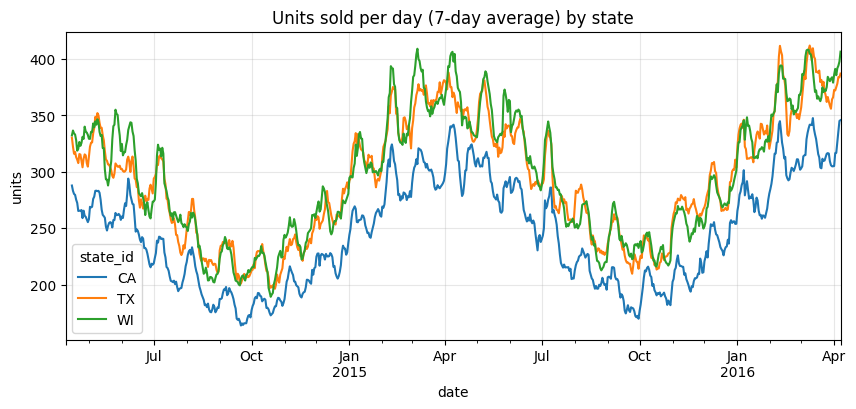

In [3]:
daily = df.groupby(["date", "state_id"])["sales"].sum().unstack()
daily.rolling(7).mean().plot(title="Units sold per day (7-day average) by state")
plt.ylabel("units"); plt.show()

## Demand by category and store

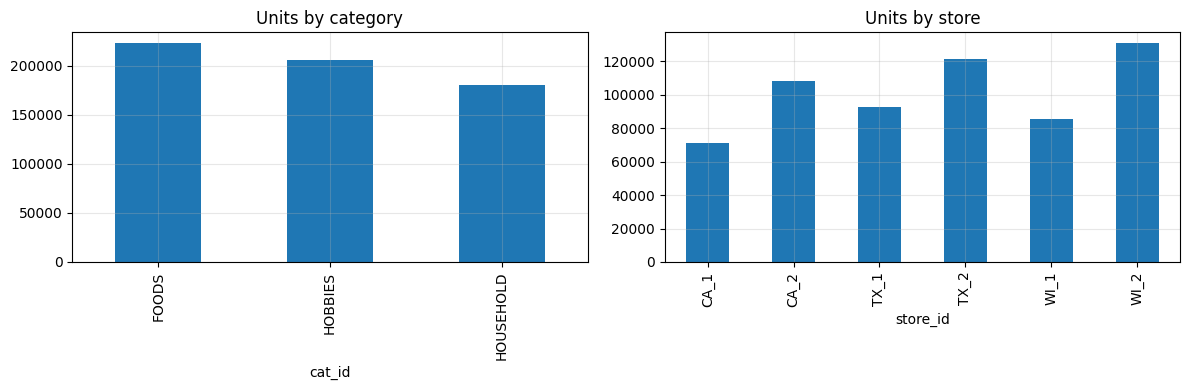

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df.groupby("cat_id")["sales"].sum().plot.bar(ax=ax[0], title="Units by category")
df.groupby("store_id")["sales"].sum().plot.bar(ax=ax[1], title="Units by store")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_hierarchy.png", dpi=120); plt.show()

**Findings (fill in after running on the real M5 data):**
- How do the 3 states / stores differ in volume?
- Which category dominates demand?
- How many series are intermittent (many zero days)? → see notebook 02.